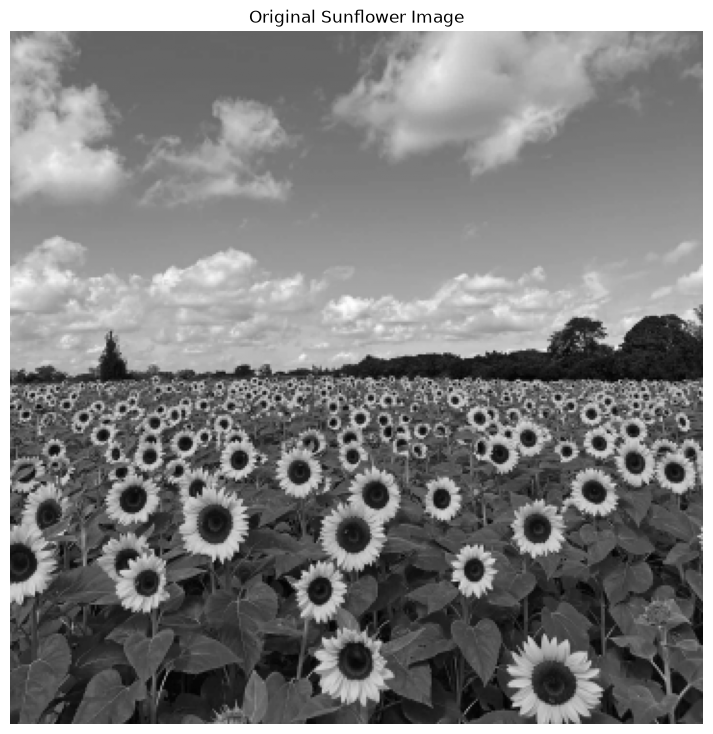

Image dimensions: (360, 360)


In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

# Read the sunflower image at a reduced resolution
image = cv.imread(
    'a2images/the_berry_farms_sunflower_field.jpeg',
    cv.IMREAD_REDUCED_COLOR_4
)

assert image is not None, "Could not load the sunflower image."

# Convert the image to grayscale and normalize pixel values
gray_image = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

# Display the input image
plt.figure(figsize=(9, 9))
plt.imshow(gray_image, cmap='gray')
plt.title('Original Sunflower Image')
plt.axis('off')
plt.show()

print("Image dimensions:", gray_image.shape)

In [2]:
# Define the scales to examine
scales = np.linspace(1, 8, 10)

# Set the threshold for accepting blob responses
response_threshold = 0.6

# Store the detected blobs
detected_blobs = []

height, width = gray_image.shape

for sigma in scales:

    print(f"Processing sigma = {sigma:.2f}")

    # Construct the LoG kernel
    half_size = round(3 * sigma)
    xx, yy = np.meshgrid(
        np.arange(-half_size, half_size + 1),
        np.arange(-half_size, half_size + 1)
    )

    distance_squared = xx**2 + yy**2

    log_kernel = (
        (distance_squared / (2 * sigma**2) - 1)
        * np.exp(-distance_squared / (2 * sigma**2))
        / (np.pi * sigma**4)
    )

    # Normalize the filter response with sigma squared
    log_kernel = sigma**2 * log_kernel

    # Apply the filter and calculate the squared response
    response = cv.filter2D(
        gray_image, cv.CV_32F, log_kernel
    )
    response = response**2

    # Find local maxima in a 3 x 3 neighbourhood
    neighbourhood_max = maximum_filter(response, size=3)

    # Keep local maxima whose responses exceed the threshold
    threshold_value = response_threshold * response.max()

    maxima_mask = (
        (response == neighbourhood_max)
        & (response >= threshold_value)
    )

    # Get the coordinates of the detected maxima
    rows, cols = np.where(maxima_mask)

    for row, col in zip(rows, cols):
        detected_blobs.append(
            (col, row, sigma, response[row, col])
        )

print("\nTotal candidate detections:", len(detected_blobs))

Processing sigma = 1.00
Processing sigma = 1.78
Processing sigma = 2.56
Processing sigma = 3.33
Processing sigma = 4.11
Processing sigma = 4.89
Processing sigma = 5.67
Processing sigma = 6.44
Processing sigma = 7.22
Processing sigma = 8.00

Total candidate detections: 131


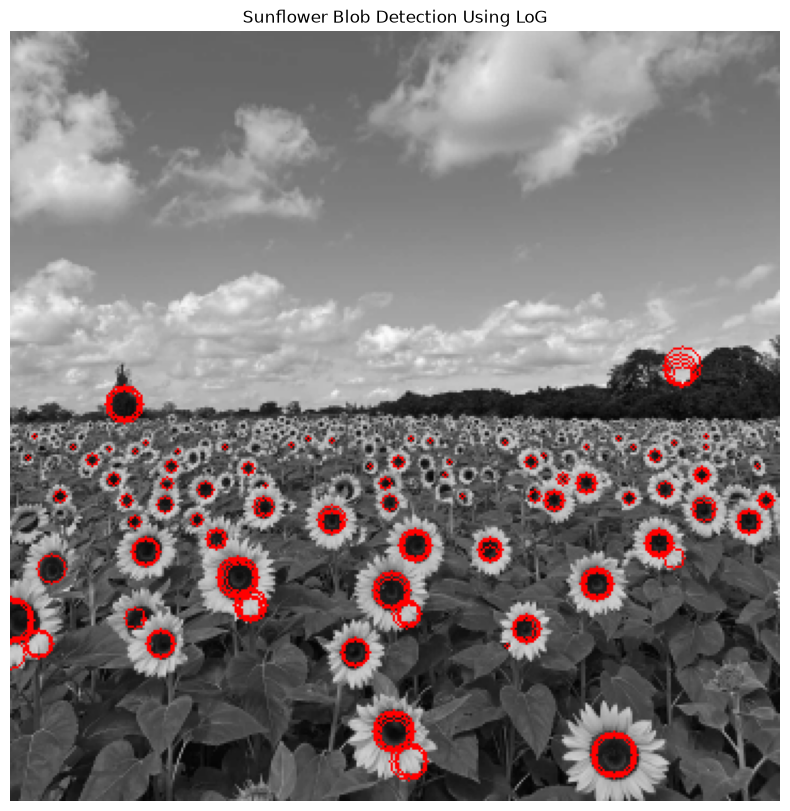

Largest detected blob:
Centre: (0, 275)
Sigma: 8.00
Radius: 11 pixels
Diameter: 22 pixels
Response strength: 0.10328


In [3]:
# Sort detections by radius, from largest to smallest
detected_blobs.sort(
    key=lambda blob: 2 * blob[2],
    reverse=True
)

# Prepare the image for drawing circles
result_image = cv.cvtColor(
    (gray_image * 255).astype(np.uint8),
    cv.COLOR_GRAY2BGR
)

# Draw all detected circles
for x, y, sigma, strength in detected_blobs:
    radius = int(round(np.sqrt(2) * sigma))

    cv.circle(
        result_image,
        (int(x), int(y)),
        radius,
        (0, 0, 255),
        1
    )

# Display the detection result
plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(result_image, cv.COLOR_BGR2RGB))
plt.title('Sunflower Blob Detection Using LoG')
plt.axis('off')
plt.show()

# Report the largest detection based on radius
if detected_blobs:
    largest_blob = max(detected_blobs, key=lambda blob: 2 * blob[2])

    x, y, sigma, strength = largest_blob
    radius = int(round(np.sqrt(2) * sigma))

    print("Largest detected blob:")
    print(f"Centre: ({x}, {y})")
    print(f"Sigma: {sigma:.2f}")
    print(f"Radius: {radius} pixels")
    print(f"Diameter: {2 * radius} pixels")
    print(f"Response strength: {strength:.5f}")
else:
    print("No blobs were detected.")

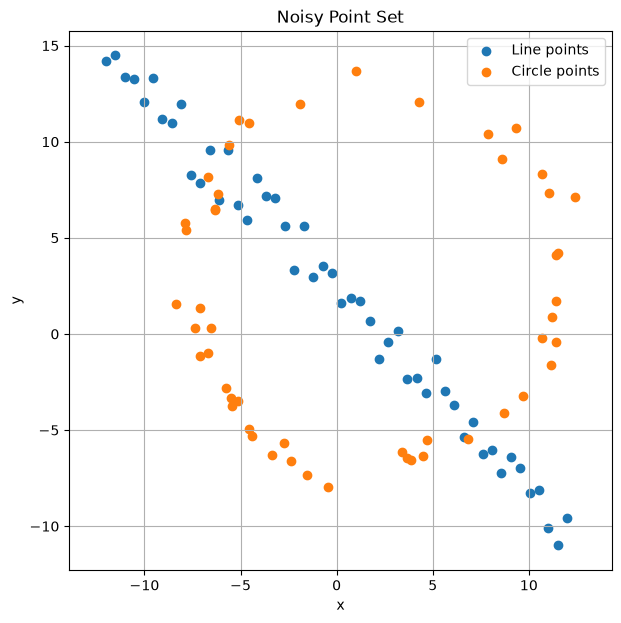

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(0)

# Generate points belonging to a circle and a line
N = 100
n_points = N // 2

# Circle parameters
radius_true = 10
center_x, center_y = 2, 3

angles = np.random.uniform(0, 2 * np.pi, n_points)
noise_circle = (radius_true / 16) * np.random.randn(n_points)

circle_x = center_x + (radius_true + noise_circle) * np.cos(angles)
circle_y = center_y + (radius_true + noise_circle) * np.sin(angles)

circle_points = np.column_stack((circle_x, circle_y))

# Line parameters
slope_true, intercept_true = -1, 2

line_x = np.linspace(-12, 12, n_points)
line_y = slope_true * line_x + intercept_true + np.random.randn(n_points)

line_points = np.column_stack((line_x, line_y))

# Combine both sets of points
points = np.vstack((circle_points, line_points))

# Display the generated data
plt.figure(figsize=(7, 7))
plt.scatter(line_points[:, 0], line_points[:, 1], label="Line points")
plt.scatter(circle_points[:, 0], circle_points[:, 1], label="Circle points")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Noisy Point Set")
plt.axis("equal")
plt.legend()
plt.grid(True)
plt.show()

In [5]:
# Calculate perpendicular distances from points to a line
def distance_to_line(model, data):
    a, b, d = model
    return np.abs(a * data[:, 0] + b * data[:, 1] + d)


# Estimate a line using RANSAC
def fit_line_ransac(data, iterations=1000, tolerance=0.6, min_consensus=35):
    best_model = None
    best_inliers = np.array([], dtype=int)

    for _ in range(iterations):
        sample = np.random.choice(len(data), 2, replace=False)
        p1, p2 = data[sample]

        a = p2[1] - p1[1]
        b = p1[0] - p2[0]
        d = -(a * p1[0] + b * p1[1])

        norm = np.sqrt(a**2 + b**2)
        if norm == 0:
            continue

        model = np.array([a, b, d]) / norm

        distances = distance_to_line(model, data)
        inlier_indices = np.where(distances < tolerance)[0]

        if (len(inlier_indices) > len(best_inliers)
                and len(inlier_indices) >= min_consensus):
            best_model = model
            best_inliers = inlier_indices

    return best_model, best_inliers


# Calculate radial distances from points to a circle
def distance_to_circle(model, data):
    cx, cy, radius = model
    distances = np.sqrt(
        (data[:, 0] - cx)**2 + (data[:, 1] - cy)**2
    )
    return np.abs(distances - radius)


# Estimate a circle using RANSAC
def fit_circle_ransac(data, iterations=1000, tolerance=1.5, min_consensus=45):
    best_model = None
    best_inliers = np.array([], dtype=int)

    for _ in range(iterations):
        sample_indices = np.random.choice(len(data), 3, replace=False)
        p1, p2, p3 = data[sample_indices]

        matrix = np.array([
            [p1[0], p1[1], 1],
            [p2[0], p2[1], 1],
            [p3[0], p3[1], 1]
        ])

        values = -np.array([
            p1[0]**2 + p1[1]**2,
            p2[0]**2 + p2[1]**2,
            p3[0]**2 + p3[1]**2
        ])

        try:
            solution = np.linalg.solve(matrix, values)
        except np.linalg.LinAlgError:
            continue

        cx = -solution[0] / 2
        cy = -solution[1] / 2
        radius_squared = cx**2 + cy**2 - solution[2]

        if radius_squared <= 0:
            continue

        radius = np.sqrt(radius_squared)
        model = np.array([cx, cy, radius])

        distances = distance_to_circle(model, data)
        inlier_indices = np.where(distances < tolerance)[0]

        if (len(inlier_indices) > len(best_inliers)
                and len(inlier_indices) >= min_consensus):
            best_model = model
            best_inliers = inlier_indices

    return best_model, best_inliers


# Fit the line first
line_model, line_inlier_indices = fit_line_ransac(points)

if line_model is None:
    raise RuntimeError("RANSAC could not find a suitable line.")

# Remove line inliers before fitting the circle
remaining_indices = np.setdiff1d(
    np.arange(len(points)), line_inlier_indices
)
remaining_points = points[remaining_indices]

circle_model, circle_inlier_indices = fit_circle_ransac(remaining_points)

if circle_model is None:
    raise RuntimeError("RANSAC could not find a suitable circle.")

# Convert circle inlier indices to indices in the original point set
circle_inlier_indices = remaining_indices[circle_inlier_indices]

print("Line model [a, b, d]:", line_model)
print("Number of line inliers:", len(line_inlier_indices))

print("\nCircle model [cx, cy, radius]:", circle_model)
print("Number of circle inliers:", len(circle_inlier_indices))

Line model [a, b, d]: [-0.7184192  -0.69561041  1.47534491]
Number of line inliers: 36

Circle model [cx, cy, radius]: [ 2.07320166  3.03114827 10.11033487]
Number of circle inliers: 52


In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the architectural image and the image to be projected
building_path = 'a2images/building1.jpg'
overlay_path = 'a2images/overlay1.jpg'

building = cv2.imread(building_path)
overlay = cv2.imread(overlay_path)

if building is None or overlay is None:
    raise FileNotFoundError("Check the image paths and filenames.")

print("Background image size:", building.shape)
print("Overlay image size:", overlay.shape)

Background image size: (480, 680, 3)
Overlay image size: (3334, 5000, 3)


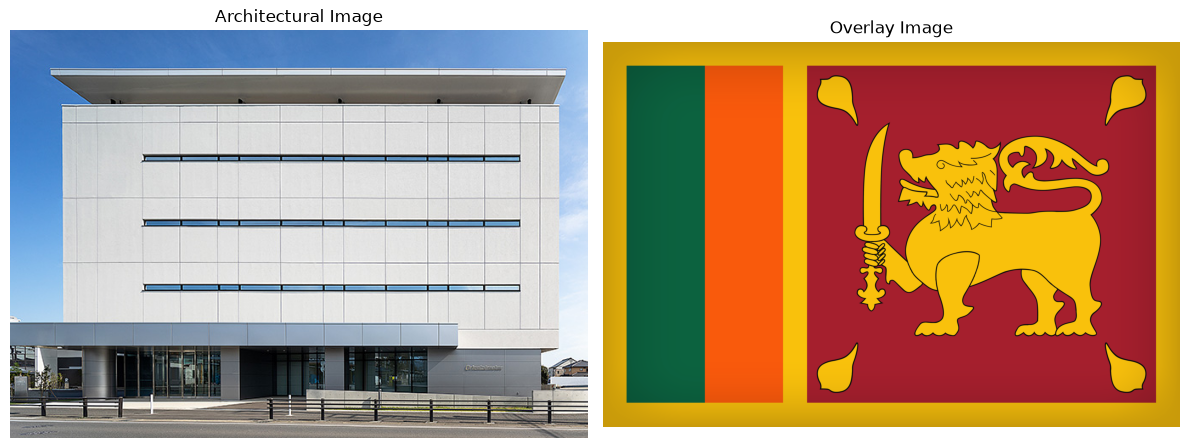

In [2]:
# Display both input images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(building, cv2.COLOR_BGR2RGB))
plt.title("Architectural Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("Overlay Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [3]:
# Make a copy for displaying the selected points
display_image = building.copy()
selected_points = []

def choose_corners(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN and len(selected_points) < 4:
        selected_points.append([x, y])

        # Mark the selected corner
        cv2.circle(display_image, (x, y), 6, (0, 255, 0), -1)
        cv2.putText(
            display_image,
            str(len(selected_points)),
            (x + 8, y - 8),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 0, 255),
            2
        )

        cv2.imshow("Select four corners", display_image)
        print(f"Selected point {len(selected_points)}: ({x}, {y})")

# Open the image window
cv2.namedWindow("Select four corners")
cv2.imshow("Select four corners", display_image)
cv2.setMouseCallback("Select four corners", choose_corners)

print("Click the four surface corners in clockwise order.")
print("Press any key after selecting all four points.")

while len(selected_points) < 4:
    if cv2.waitKey(20) & 0xFF == 27:
        break

cv2.waitKey(0)
cv2.destroyAllWindows()

if len(selected_points) != 4:
    raise ValueError("Exactly four points must be selected.")

destination_points = np.array(selected_points, dtype=np.float32)

# Get the four corners of the overlay image
overlay_height, overlay_width = overlay.shape[:2]

source_points = np.array([
    [0, 0],
    [overlay_width - 1, 0],
    [overlay_width - 1, overlay_height - 1],
    [0, overlay_height - 1]
], dtype=np.float32)

# Compute the homography mapping overlay coordinates to the surface
H, status = cv2.findHomography(source_points, destination_points)

if H is None:
    raise RuntimeError("Homography estimation failed.")

print("Homography matrix:")
print(H)

Click the four surface corners in clockwise order.
Press any key after selecting all four points.
Selected point 1: (156, 108)
Selected point 2: (517, 109)
Selected point 3: (517, 275)
Selected point 4: (156, 275)
Homography matrix:
[[ 7.28374591e-02 -1.36283707e-17  1.56000000e+02]
 [ 3.31391580e-04  5.01050105e-02  1.08000000e+02]
 [ 1.20506029e-06 -4.05003587e-20  1.00000000e+00]]


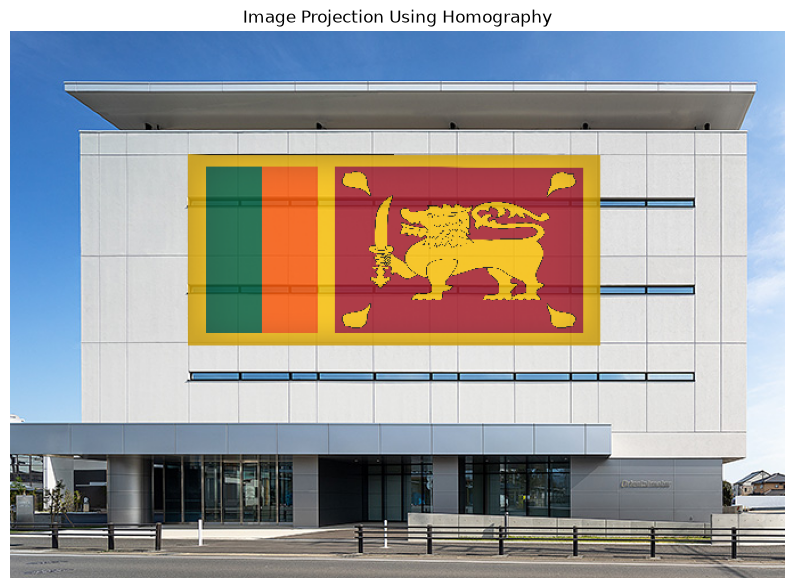

Result saved as: homography_result1.png


In [4]:
# Warp the overlay into the background image coordinates
height, width = building.shape[:2]

warped_overlay = cv2.warpPerspective(
    overlay,
    H,
    (width, height)
)

# Create a mask for the projected quadrilateral
surface_mask = np.zeros((height, width), dtype=np.uint8)

cv2.fillConvexPoly(
    surface_mask,
    destination_points.astype(np.int32),
    255
)

# Blend only within the selected surface
alpha = 0.85

result = building.copy()

region = surface_mask > 0

result[region] = cv2.addWeighted(
    building[region],
    1 - alpha,
    warped_overlay[region],
    alpha,
    0
)

# Display the final composite
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Image Projection Using Homography")
plt.axis("off")
plt.show()

# Save the result
output_path = "homography_result1.png"
cv2.imwrite(output_path, result)

print("Result saved as:", output_path)

Background image size: (4999, 4000, 3)
Overlay image size: (800, 800, 3)


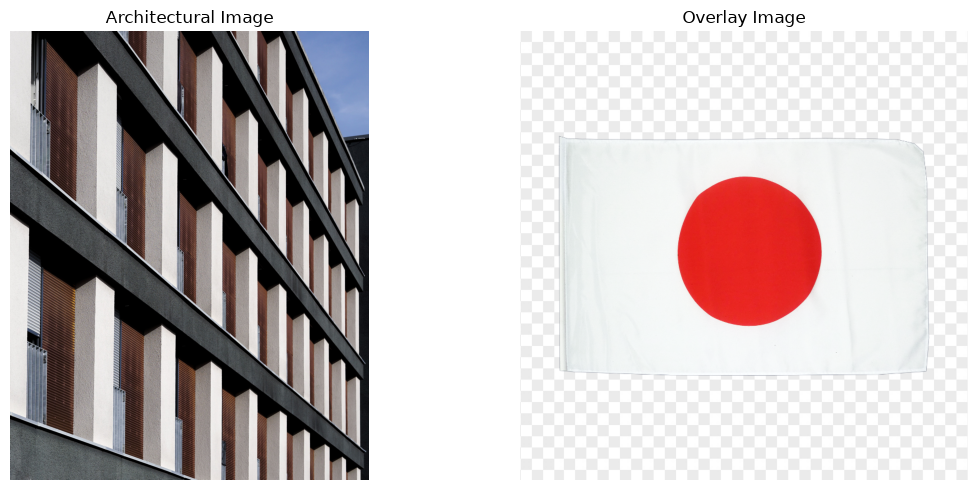

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the architectural image and the image to be projected
building_path = 'a2images/building2.jpg'
overlay_path = 'a2images/flag2.png'

building = cv2.imread(building_path)
overlay = cv2.imread(overlay_path)

if building is None or overlay is None:
    raise FileNotFoundError("Check the image paths and filenames.")

print("Background image size:", building.shape)
print("Overlay image size:", overlay.shape)

# Display both input images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(building, cv2.COLOR_BGR2RGB))
plt.title("Architectural Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("Overlay Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Make a copy for displaying the selected points
display_image = building.copy()
selected_points = []

def choose_corners(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN and len(selected_points) < 4:
        selected_points.append([x, y])

        # Mark the selected corner
        cv2.circle(display_image, (x, y), 6, (0, 255, 0), -1)
        cv2.putText(
            display_image,
            str(len(selected_points)),
            (x + 8, y - 8),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 0, 255),
            2
        )

        cv2.imshow("Select four corners", display_image)
        print(f"Selected point {len(selected_points)}: ({x}, {y})")

# Open the image window
cv2.namedWindow("Select four corners")
cv2.imshow("Select four corners", display_image)
cv2.setMouseCallback("Select four corners", choose_corners)

print("Click the four surface corners in clockwise order.")
print("Press any key after selecting all four points.")

while len(selected_points) < 4:
    if cv2.waitKey(20) & 0xFF == 27:
        break

cv2.waitKey(0)
cv2.destroyAllWindows()

if len(selected_points) != 4:
    raise ValueError("Exactly four points must be selected.")

destination_points = np.array(selected_points, dtype=np.float32)

# Get the four corners of the overlay image
overlay_height, overlay_width = overlay.shape[:2]

source_points = np.array([
    [0, 0],
    [overlay_width - 1, 0],
    [overlay_width - 1, overlay_height - 1],
    [0, overlay_height - 1]
], dtype=np.float32)

# Compute the homography mapping overlay coordinates to the surface
H, status = cv2.findHomography(source_points, destination_points)

if H is None:
    raise RuntimeError("Homography estimation failed.")

print("Homography matrix:")
print(H)

Click the four surface corners in clockwise order.
Press any key after selecting all four points.


KeyboardInterrupt: 

In [8]:
# Warp the overlay into the background image coordinates
height, width = building.shape[:2]

warped_overlay = cv2.warpPerspective(
    overlay,
    H,
    (width, height)
)

# Create a mask for the projected quadrilateral
surface_mask = np.zeros((height, width), dtype=np.uint8)

cv2.fillConvexPoly(
    surface_mask,
    destination_points.astype(np.int32),
    255
)

# Blend only within the selected surface
alpha = 0.85

result = building.copy()

region = surface_mask > 0

result[region] = cv2.addWeighted(
    building[region],
    1 - alpha,
    warped_overlay[region],
    alpha,
    0
)

# Display the final composite
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Image Projection Using Homography")
plt.axis("off")
plt.show()

# Save the result
output_path = "homography_result2.png"
cv2.imwrite(output_path, result)

print("Result saved as:", output_path)

NameError: name 'H' is not defined

Reference image: AECC1.jpg
Reference image dimensions: 2302 x 2730
Reference keypoints: 14274

Processing AAAA1.jpg...
Good matches: 51
RANSAC inliers: 18
Inlier ratio: 0.353
Saved results for AAAA1.jpg

Processing ADAD1.jpg...
Good matches: 370
RANSAC inliers: 195
Inlier ratio: 0.527
Saved results for ADAD1.jpg

Processing AECC2.jpg...
Good matches: 4321
RANSAC inliers: 3846
Inlier ratio: 0.89
Saved results for AECC2.jpg

Processing AECC3.jpg...
Good matches: 5629
RANSAC inliers: 5006
Inlier ratio: 0.889
Saved results for AECC3.jpg

Processing AECC4.jpg...
Good matches: 3830
RANSAC inliers: 3402
Inlier ratio: 0.888
Saved results for AECC4.jpg


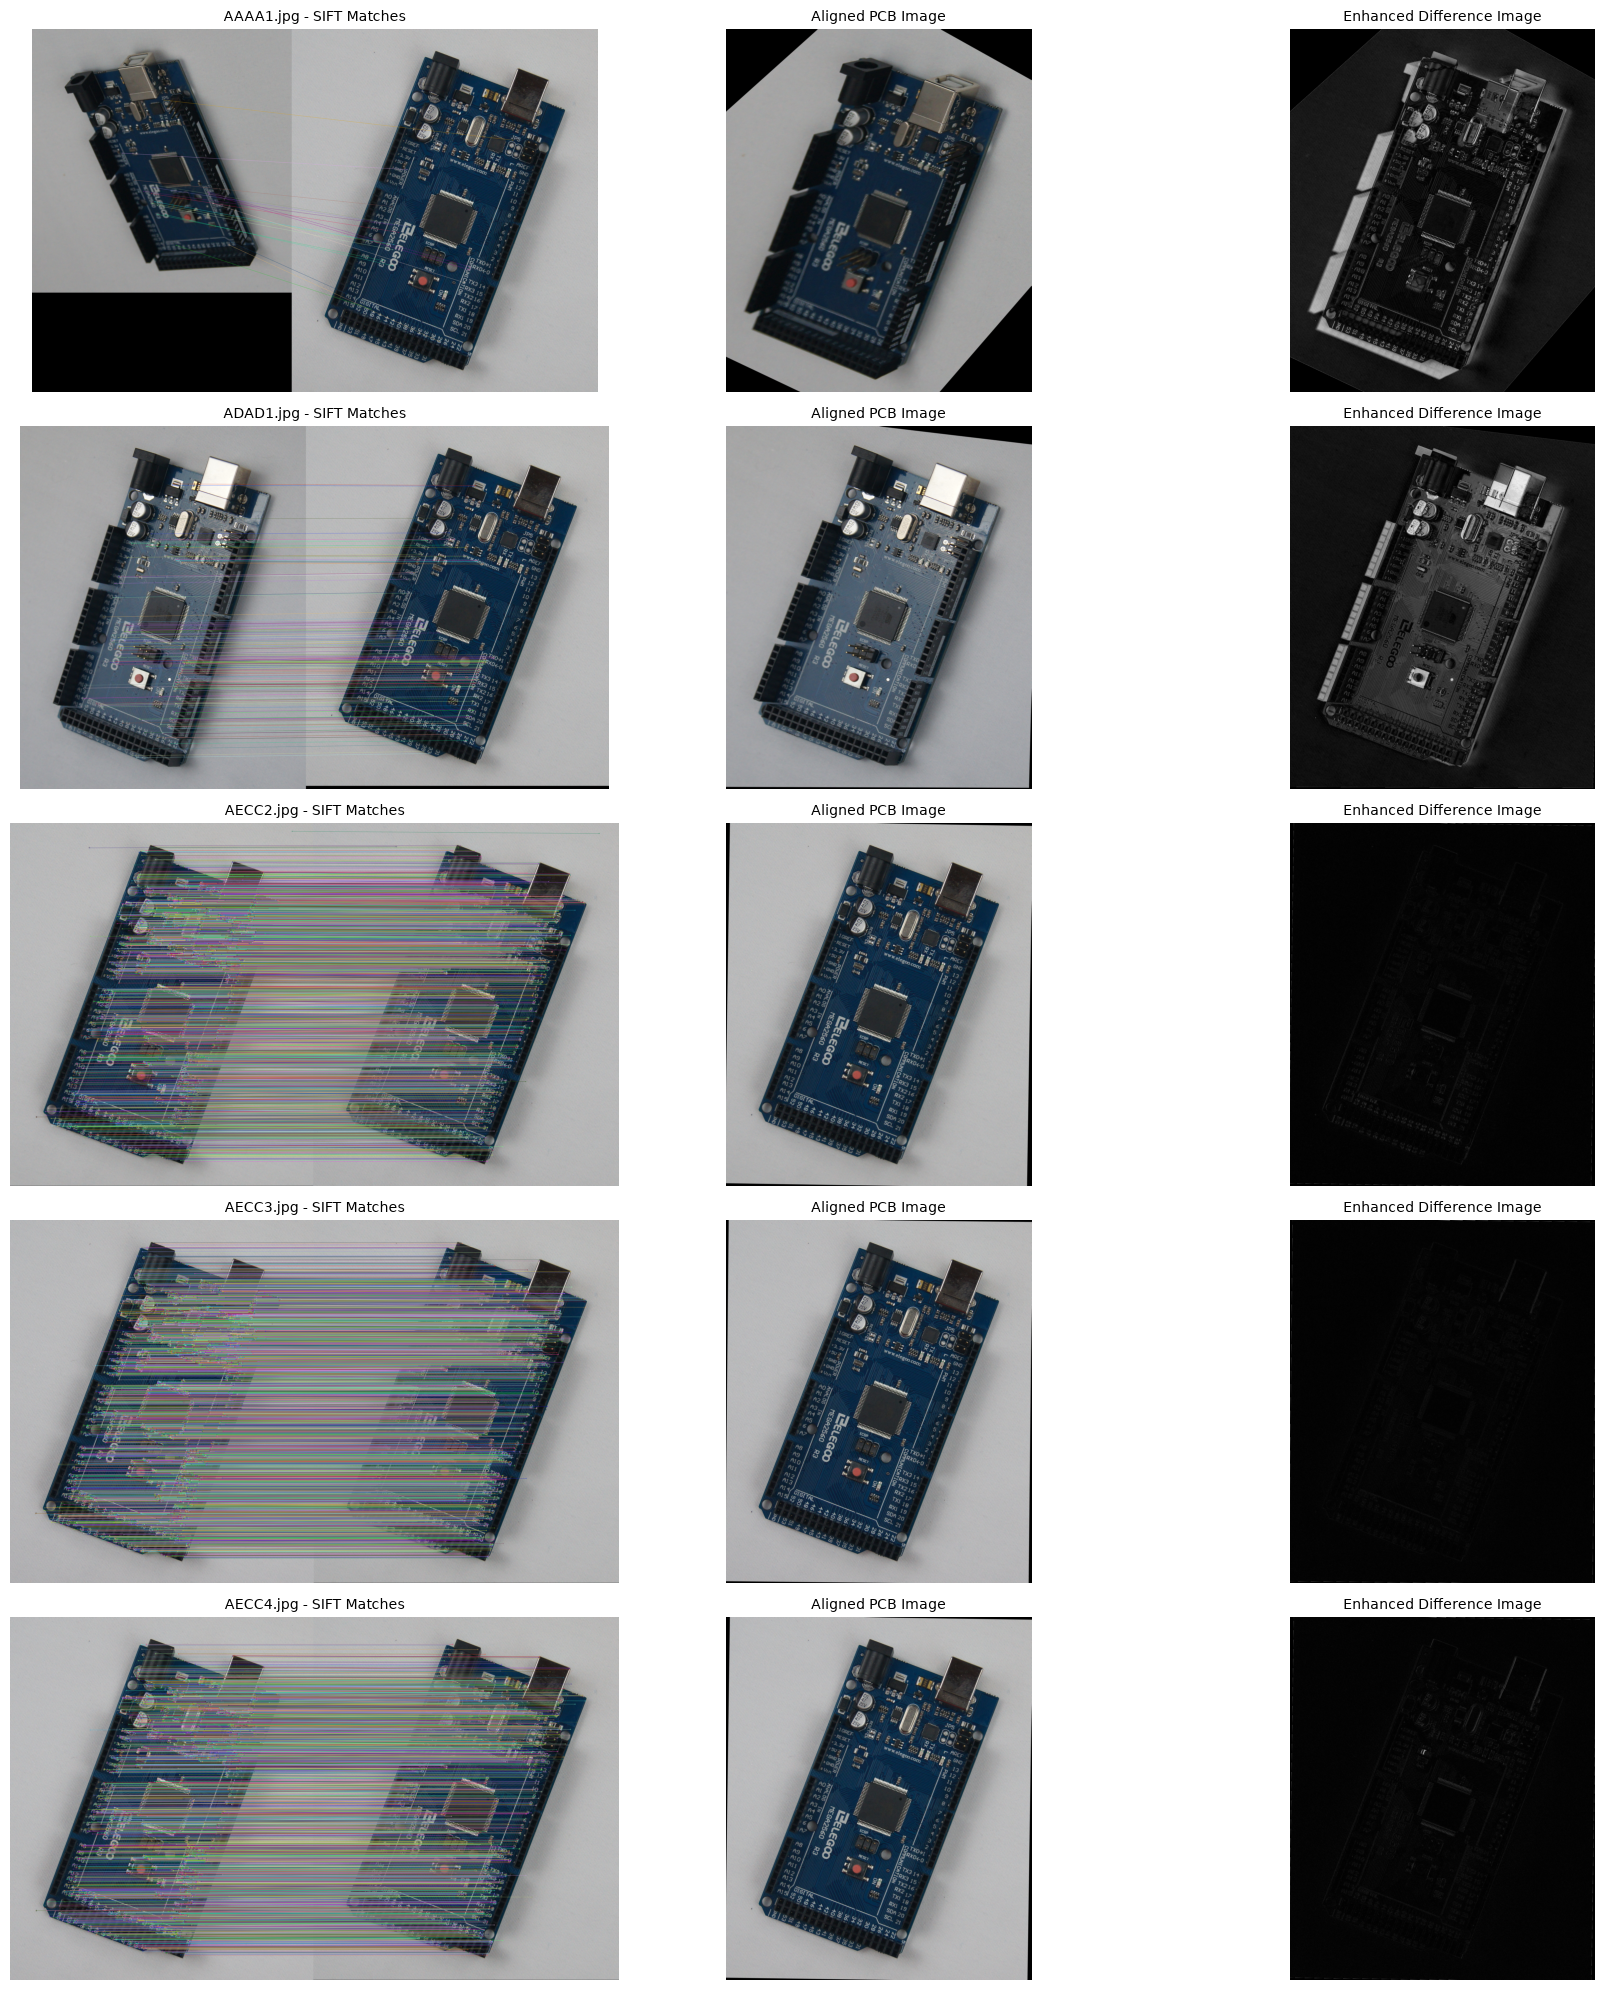


All PCB images processed successfully.
Number of processed images: 5
Individual results: pcb_alignment_results
Combined figure: pcb_alignment_results/all_pcb_results.png


In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# ==================================================
# 1. Load the reference image
# ==================================================

template_path = 'a2images/AECC1.jpg'
template = cv2.imread(template_path)

if template is None:
    raise FileNotFoundError(
        f"Cannot load reference image: {template_path}"
    )

template_gray = cv2.cvtColor(
    template, cv2.COLOR_BGR2GRAY
)

height, width = template.shape[:2]

print("Reference image: AECC1.jpg")
print("Reference image dimensions:", width, "x", height)

# ==================================================
# 2. Detect SIFT features in the reference image
# ==================================================

sift = cv2.SIFT_create()

template_keypoints, template_descriptors = (
    sift.detectAndCompute(template_gray, None)
)

if template_descriptors is None:
    raise RuntimeError(
        "No SIFT features detected in AECC1.jpg."
    )

matcher = cv2.BFMatcher(cv2.NORM_L2)

print("Reference keypoints:", len(template_keypoints))

# ==================================================
# 3. Specify the five PCB images
# ==================================================

pcb_names = [
    'AAAA1.jpg',
    'ADAD1.jpg',
    'AECC2.jpg',
    'AECC3.jpg',
    'AECC4.jpg'
]

output_folder = 'pcb_alignment_results'
os.makedirs(output_folder, exist_ok=True)

# Store the results for the combined figure
all_results = []

# ==================================================
# 4. Process each PCB image
# ==================================================

for pcb_name in pcb_names:

    pcb_path = f'a2images/{pcb_name}'
    pcb = cv2.imread(pcb_path)

    if pcb is None:
        print(f"\nCannot load {pcb_name}. Skipping.")
        continue

    print(f"\nProcessing {pcb_name}...")

    # Convert PCB image to grayscale
    pcb_gray = cv2.cvtColor(
        pcb, cv2.COLOR_BGR2GRAY
    )

    # ----------------------------------------------
    # Detect SIFT features
    # ----------------------------------------------

    pcb_keypoints, pcb_descriptors = (
        sift.detectAndCompute(pcb_gray, None)
    )

    if pcb_descriptors is None or len(pcb_keypoints) < 4:
        print("Insufficient SIFT features. Skipping.")
        continue

    # ----------------------------------------------
    # Match descriptors
    # ----------------------------------------------

    candidate_matches = matcher.knnMatch(
        pcb_descriptors,
        template_descriptors,
        k=2
    )

    # Lowe's ratio test
    good_matches = [
        pair[0]
        for pair in candidate_matches
        if len(pair) == 2
        and pair[0].distance < 0.75 * pair[1].distance
    ]

    print("Good matches:", len(good_matches))

    if len(good_matches) < 4:
        print("Insufficient matches for homography.")
        continue

    # ----------------------------------------------
    # Obtain corresponding feature coordinates
    # ----------------------------------------------

    pcb_points = np.float32([
        pcb_keypoints[m.queryIdx].pt
        for m in good_matches
    ]).reshape(-1, 1, 2)

    template_points = np.float32([
        template_keypoints[m.trainIdx].pt
        for m in good_matches
    ]).reshape(-1, 1, 2)

    # ----------------------------------------------
    # Estimate homography using RANSAC
    # ----------------------------------------------

    H, inlier_mask = cv2.findHomography(
        pcb_points,
        template_points,
        cv2.RANSAC,
        5.0
    )

    if H is None or inlier_mask is None:
        print("Homography estimation failed. Skipping.")
        continue

    inlier_count = int(inlier_mask.sum())
    inlier_ratio = float(inlier_mask.mean())

    print("RANSAC inliers:", inlier_count)
    print("Inlier ratio:", round(inlier_ratio, 3))

    # ----------------------------------------------
    # Draw SIFT matches accepted by RANSAC
    # ----------------------------------------------

    match_image = cv2.drawMatches(
        pcb,
        pcb_keypoints,
        template,
        template_keypoints,
        good_matches,
        None,
        matchesMask=inlier_mask.ravel().tolist(),
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    # ==================================================
    # 5. Align the PCB image with the reference
    # ==================================================

    aligned_image = cv2.warpPerspective(
        pcb,
        H,
        (width, height)
    )

    # Create a mask identifying valid source pixels
    source_mask = np.full(
        pcb.shape[:2],
        255,
        dtype=np.uint8
    )

    aligned_mask = cv2.warpPerspective(
        source_mask,
        H,
        (width, height)
    )

    # ==================================================
    # 6. Calculate the difference image
    # ==================================================

    difference_image = cv2.absdiff(
        template,
        aligned_image
    )

    # Exclude areas outside the warped source image
    difference_image[aligned_mask == 0] = 0

    # Convert the difference image to grayscale
    gray_difference = cv2.cvtColor(
        difference_image,
        cv2.COLOR_BGR2GRAY
    )

    # Enhance contrast for visualization
    enhanced_difference = cv2.normalize(
        gray_difference,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    # ==================================================
    # 7. Save individual result images
    # ==================================================

    image_id = os.path.splitext(pcb_name)[0]

    cv2.imwrite(
        os.path.join(
            output_folder,
            f'{image_id}_matches.png'
        ),
        match_image
    )

    cv2.imwrite(
        os.path.join(
            output_folder,
            f'{image_id}_aligned.png'
        ),
        aligned_image
    )

    cv2.imwrite(
        os.path.join(
            output_folder,
            f'{image_id}_difference.png'
        ),
        difference_image
    )

    cv2.imwrite(
        os.path.join(
            output_folder,
            f'{image_id}_difference_enhanced.png'
        ),
        enhanced_difference
    )

    # Store images for the combined figure
    all_results.append((
        pcb_name,
        match_image,
        aligned_image,
        enhanced_difference
    ))

    print("Saved results for", pcb_name)

# ==================================================
# 8. Create one combined figure containing all results
# ==================================================

if len(all_results) == 0:
    raise RuntimeError(
        "No PCB images were processed successfully."
    )

number_of_rows = len(all_results)

fig, axes = plt.subplots(
    number_of_rows,
    3,
    figsize=(18, 4 * number_of_rows),
    squeeze=False
)

for row, (pcb_name, match_img, aligned_img, diff_img) in enumerate(
    all_results
):

    # ----------------------------------------------
    # Column 1: SIFT matches
    # ----------------------------------------------

    axes[row, 0].imshow(
        cv2.cvtColor(
            match_img,
            cv2.COLOR_BGR2RGB
        )
    )

    axes[row, 0].set_title(
        f'{pcb_name} - SIFT Matches',
        fontsize=10
    )

    axes[row, 0].axis('off')

    # ----------------------------------------------
    # Column 2: Aligned PCB image
    # ----------------------------------------------

    axes[row, 1].imshow(
        cv2.cvtColor(
            aligned_img,
            cv2.COLOR_BGR2RGB
        )
    )

    axes[row, 1].set_title(
        'Aligned PCB Image',
        fontsize=10
    )

    axes[row, 1].axis('off')

    # ----------------------------------------------
    # Column 3: Enhanced difference image
    # ----------------------------------------------

    axes[row, 2].imshow(
        diff_img,
        cmap='gray',
        vmin=0,
        vmax=255
    )

    axes[row, 2].set_title(
        'Enhanced Difference Image',
        fontsize=10
    )

    axes[row, 2].axis('off')

# Adjust layout
plt.tight_layout()

# Save the combined figure
combined_path = os.path.join(
    output_folder,
    'all_pcb_results.png'
)

plt.savefig(
    combined_path,
    dpi=200,
    bbox_inches='tight'
)

plt.show()

# ==================================================
# 9. Completion message
# ==================================================

print("\n======================================")
print("All PCB images processed successfully.")
print("Number of processed images:", len(all_results))
print("Individual results:", output_folder)
print("Combined figure:", combined_path)
print("======================================")